In [10]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from collections import Counter
from rank_bm25 import BM25Okapi
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

pd.set_option("display.max_colwidth", 120)

# Load dataset hasil split dari Stage 2 (Baseline)
corpus = pd.read_csv("../corpus_faq.csv")
dev_df = pd.read_csv("../queries_dev.csv")
test_df = pd.read_csv("../queries_test.csv")

print(f"Corpus  : {corpus.shape}")
print(f"Dev set : {dev_df.shape}")
print(f"Test set: {test_df.shape}")

Corpus  : (40, 4)
Dev set : (166, 7)
Test set: (499, 7)


In [11]:
stemmer = StemmerFactory().create_stemmer()
stopword_remover = StopWordRemoverFactory()
stopwords_id = set(stopword_remover.get_stop_words())

_stem_cache = {}
def stem_cached(token):
    if token not in _stem_cache:
        _stem_cache[token] = stemmer.stem(token)
    return _stem_cache[token]

def case_fold(text):
    return text.lower()

def clean_regex(text):
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def tokenize(text):
    return text.split()

def remove_stopwords(tokens):
    return [t for t in tokens if t not in stopwords_id]

def preprocess_standard(text, do_stem=True, do_stopword=True):
    text = clean_regex(case_fold(text))
    tokens = tokenize(text)
    if do_stopword:
        tokens = remove_stopwords(tokens)
    if do_stem:
        tokens = [stem_cached(t) for t in tokens]
    return tokens

# Indeks dokumen korpus FAQ (pertanyaan_baku + jawaban)
corpus["teks_indeks"] = corpus["pertanyaan_baku"] + " " + corpus["jawaban"]
corpus["tokens"] = corpus["teks_indeks"].apply(preprocess_standard)

# Bangun Kosakata Acuan (Reference Vocabulary) dari permukaan kata korpus (sebelum stemming)
# serta permukaan kata dari pertanyaan_baku agar kata berimbuhan di korpus dikenali secara utuh
corpus_surface_tokens = []
for teks in corpus["teks_indeks"]:
    toks = remove_stopwords(tokenize(clean_regex(case_fold(teks))))
    corpus_surface_tokens.extend(toks)

# Tambahkan pula kosakata hasil stemming korpus sebagai pelengkap acuan
corpus_stemmed_tokens = [w for toks in corpus["tokens"] for w in toks]

vocab_freq = Counter(corpus_surface_tokens + corpus_stemmed_tokens)
vocab_acuan = set(vocab_freq.keys())

# Bangun indeks BM25
corpus_tokens = corpus["tokens"].tolist()
doc_ids = corpus["doc_id"].tolist()
bm25 = BM25Okapi(corpus_tokens)

print(f"Ukuran Kosakata Acuan (Permukaan + Dasar): {len(vocab_acuan)} kata unik")
print(f"Ukuran Kosakata Indeks BM25 (Ter-stem)   : {len(set(corpus_stemmed_tokens))} token")

Ukuran Kosakata Acuan (Permukaan + Dasar): 449 kata unik
Ukuran Kosakata Indeks BM25 (Ter-stem)   : 290 token


In [12]:
# Memperbarui vocab_acuan agar menyertakan stopwords_id (sehingga typo pada stopword
# seperti 'sduah' -> 'sudah' terkoreksi menjadi stopword lalu terhapus di tahap kedua)
vocab_acuan = vocab_acuan.union(stopwords_id)

def levenshtein_distance(s1, s2):
    """
    Menghitung jumlah minimum operasi penyisipan (insertion),
    penghapusan (deletion), dan penggantian (substitution) karakter
    untuk mengubah kata s1 menjadi s2 menggunakan Dynamic Programming.
    """
    if len(s1) < len(s2):
        return levenshtein_distance(s2, s1)
    if len(s2) == 0:
        return len(s1)

    previous_row = list(range(len(s2) + 1))
    for i, c1 in enumerate(s1):
        current_row = [i + 1]
        for j, c2 in enumerate(s2):
            insertions = previous_row[j + 1] + 1
            deletions = current_row[j] + 1
            substitutions = previous_row[j] + (c1 != c2)
            current_row.append(min(insertions, deletions, substitutions))
        previous_row = current_row

    return previous_row[-1]

_lev_cache = {}
def cari_kandidat_terdekat(token, vocab_set, freq_counter):
    """
    Mencari kandidat kata di vocab_set dengan Levenshtein distance terkecil.
    Jika ada beberapa kandidat dengan jarak minimum yang sama, dipilih kandidat
    dengan frekuensi tertinggi pada korpus acuan.
    """
    if token in _lev_cache:
        return _lev_cache[token]

    best_candidate = token
    min_dist = float("inf")
    best_freq = -1

    for cand in vocab_set:
        # Pruning selisih panjang kata untuk mempercepat komputasi
        if abs(len(token) - len(cand)) > min_dist:
            continue
        dist = levenshtein_distance(token, cand)
        cand_freq = freq_counter[cand]
        if (dist < min_dist) or (dist == min_dist and cand_freq > best_freq):
            min_dist = dist
            best_candidate = cand
            best_freq = cand_freq

    _lev_cache[token] = (best_candidate, min_dist)
    return best_candidate, min_dist

def koreksi_token_levenshtein(token, threshold, vocab_set, freq_counter, min_word_len=3):
    """
    Mengoreksi token jika tidak ditemukan di vocab_set (maupun bentuk dasarnya)
    dan jarak <= effective_threshold.
    """
    if threshold <= 0:
        return token, 0, False

    # Jika token atau hasil stem-nya sudah ada di kosakata acuan, jangan dikoreksi
    stemmed_tok = stem_cached(token)
    if (token in vocab_set) or (stemmed_tok in vocab_set) or token.isdigit() or len(token) < min_word_len:
        return token, 0, False

    kandidat, dist = cari_kandidat_terdekat(token, vocab_set, freq_counter)

    # Batasi d <= 1 untuk kata pendek (3-4 karakter) guna mencegah over-correction (mis. sdh -> spk)
    effective_threshold = min(threshold, 1) if len(token) <= 4 else threshold

    if dist <= effective_threshold:
        return kandidat, dist, True
    return token, dist, False

def preprocess_levenshtein(text, threshold, vocab_set, freq_counter):
    text = clean_regex(case_fold(text))
    tokens = remove_stopwords(tokenize(text))
    corrected_tokens = []
    for t in tokens:
        corr_t, _, _ = koreksi_token_levenshtein(t, threshold, vocab_set, freq_counter)
        corrected_tokens.append(corr_t)
    # Hapus stopword kembali jika hasil koreksi menghasilkan stopword, lalu stem
    corrected_tokens = remove_stopwords(corrected_tokens)
    stemmed_tokens = [stem_cached(t) for t in corrected_tokens]
    return stemmed_tokens

In [13]:
# Menampilkan contoh perubahan token pada kueri bergaya 'typo' di dev_df
sample_typos = dev_df[dev_df["gaya_kueri"] == "typo"].head(8)

for _, row in sample_typos.iterrows():
    raw_toks = remove_stopwords(tokenize(clean_regex(case_fold(row["query_text"]))))
    corr_log = []
    for t in raw_toks:
        c, d, changed = koreksi_token_levenshtein(t, threshold=2, vocab_set=vocab_acuan, freq_counter=vocab_freq)
        if changed:
            corr_log.append(f"{t} -> {c} (d={d})")
    print(f"[{row['query_id']}] Asli     : {row['query_text']}")
    print(f"        Koreksi  : {', '.join(corr_log) if corr_log else '(tidak ada token dikoreksi)'}")
    print(f"        BM25 Tok : {preprocess_levenshtein(row['query_text'], 2, vocab_acuan, vocab_freq)}\n")

[Q0380] Asli     : nama aKprodi di dokumen IA masih menggunaakn nama lama padahal sudah ada pergantina, apakah perlu disesuaiakn
        Koreksi  : akprodi -> kaprodi (d=2), menggunaakn -> menggunakan (d=2), pergantina -> pergantian (d=2), disesuaiakn -> disesuaikan (d=2)
        BM25 Tok : ['nama', 'kaprodi', 'dokumen', 'guna', 'nama', 'lama', 'padahal', 'ganti', 'perlu', 'sesuai']

[Q0490] Asli     : berapa lama batsa waktu pelaksanaan semianr PI setelah hari penarikan
        Koreksi  : batsa -> data (d=2), semianr -> seminar (d=2)
        BM25 Tok : ['berapa', 'lama', 'data', 'waktu', 'laksana', 'seminar', 'pi', 'hari', 'tari']

[Q0572] Asli     : niai PI yang diupload itu nilai dari temat PI atau nilai sesudah semnar
        Koreksi  : niai -> nilai (d=1), temat -> tempat (d=1), semnar -> seminar (d=1)
        BM25 Tok : ['nilai', 'pi', 'diupload', 'nilai', 'tempat', 'pi', 'nilai', 'seminar']

[Q0253] Asli     : harusnya saya 3 orang ibu, tapi baru 2 rang dan sudah disetujui dmin,

In [14]:
def evaluate_levenshtein(df, bm25_index, doc_ids_list, threshold, vocab_set, freq_counter):
    hits_at_1 = 0
    hits_at_3 = 0
    hits_at_5 = 0
    reciprocal_ranks = []
    total_tokens = 0
    corrected_count = 0
    n = len(df)

    for _, row in df.iterrows():
        raw_toks = remove_stopwords(tokenize(clean_regex(case_fold(row["query_text"]))))
        q_corr = []
        for t in raw_toks:
            total_tokens += 1
            c, _, changed = koreksi_token_levenshtein(t, threshold, vocab_set, freq_counter)
            if changed:
                corrected_count += 1
            q_corr.append(c)

        q_tokens = [stem_cached(t) for t in remove_stopwords(q_corr)]
        scores = bm25_index.get_scores(q_tokens)
        ranked_idx = np.argsort(scores)[::-1]
        ranked_docs = [doc_ids_list[i] for i in ranked_idx]

        true_doc = row["relevant_doc_id"]
        if ranked_docs[0] == true_doc:
            hits_at_1 += 1
        if true_doc in ranked_docs[:3]:
            hits_at_3 += 1
        if true_doc in ranked_docs[:5]:
            hits_at_5 += 1

        rank = ranked_docs.index(true_doc) + 1
        reciprocal_ranks.append(1.0 / rank)

    return {
        "Threshold": threshold,
        "Hit@1": hits_at_1 / n,
        "Hit@3": hits_at_3 / n,
        "Hit@5": hits_at_5 / n,
        "MRR": np.mean(reciprocal_ranks),
        "Token_Terkoreksi": corrected_count,
        "Rasio_Koreksi": corrected_count / max(total_tokens, 1),
        "n": n
    }

# Uji variasi threshold d in {0 (Baseline), 1, 2, 3} pada Dev Set
thresholds = [0, 1, 2, 3]
dev_tuning_results = []

for th in thresholds:
    res = evaluate_levenshtein(dev_df, bm25, doc_ids, th, vocab_acuan, vocab_freq)
    # Evaluasi khusus pada subset gaya_kueri == 'typo' di Dev Set
    res_typo = evaluate_levenshtein(
        dev_df[dev_df["gaya_kueri"] == "typo"], bm25, doc_ids, th, vocab_acuan, vocab_freq
    )
    res["Hit@1_Typo"] = res_typo["Hit@1"]
    res["MRR_Typo"] = res_typo["MRR"]
    dev_tuning_results.append(res)

tuning_df = pd.DataFrame(dev_tuning_results)
print("=== Hasil Pengujian Ambang Batas (Threshold) Levenshtein pada Development Set ===")
display(tuning_df.round(4))

# Pilih threshold terbaik berdasarkan MRR (dan Hit@1) tertinggi pada Dev Set
best_row = tuning_df.loc[tuning_df["Threshold"] > 0].sort_values(by=["MRR", "Hit@1"], ascending=False).iloc[0]
best_threshold = int(best_row["Threshold"])
print(f"\n-> Ambang batas (threshold) optimal pada Development Set: d <= {best_threshold}")

=== Hasil Pengujian Ambang Batas (Threshold) Levenshtein pada Development Set ===


,Threshold,Hit@1,Hit@3,Hit@5,MRR,Token_Terkoreksi,Rasio_Koreksi,n,Hit@1_Typo,MRR_Typo
0,0,0.9398,0.9819,0.988,0.9620,0,0.0000,166,0.875,0.9132
1,1,0.9639,0.9940,0.994,0.9789,141,0.0884,166,0.925,0.9583
2,2,0.9759,1.0000,1.000,0.9869,226,0.1417,166,0.925,0.9583
3,3,0.9759,1.0000,1.000,0.9859,259,0.1624,166,0.925,0.9583



-> Ambang batas (threshold) optimal pada Development Set: d <= 2


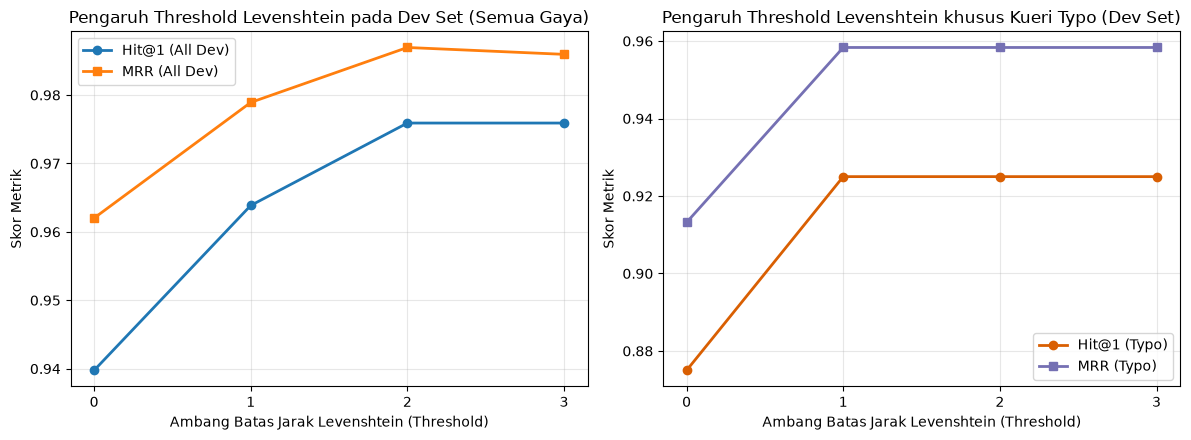

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot 1: Performa Keseluruhan Dev Set
ax[0].plot(tuning_df["Threshold"], tuning_df["Hit@1"], marker="o", linewidth=2, label="Hit@1 (All Dev)")
ax[0].plot(tuning_df["Threshold"], tuning_df["MRR"], marker="s", linewidth=2, label="MRR (All Dev)")
ax[0].set_title("Pengaruh Threshold Levenshtein pada Dev Set (Semua Gaya)")
ax[0].set_xlabel("Ambang Batas Jarak Levenshtein (Threshold)")
ax[0].set_ylabel("Skor Metrik")
ax[0].set_xticks(thresholds)
ax[0].grid(alpha=0.3)
ax[0].legend()

# Plot 2: Performa Khusus Kueri Typo pada Dev Set
ax[1].plot(tuning_df["Threshold"], tuning_df["Hit@1_Typo"], marker="o", color="#d95f02", linewidth=2, label="Hit@1 (Typo)")
ax[1].plot(tuning_df["Threshold"], tuning_df["MRR_Typo"], marker="s", color="#7570b3", linewidth=2, label="MRR (Typo)")
ax[1].set_title("Pengaruh Threshold Levenshtein khusus Kueri Typo (Dev Set)")
ax[1].set_xlabel("Ambang Batas Jarak Levenshtein (Threshold)")
ax[1].set_ylabel("Skor Metrik")
ax[1].set_xticks(thresholds)
ax[1].grid(alpha=0.3)
ax[1].legend()

plt.tight_layout()
plt.savefig("fig_tuning_threshold_levenshtein_dev.png", dpi=150)
plt.show()

In [16]:
order = ["formal", "informal", "singkatan", "parafrase", "typo"]

# 1. Evaluasi Keseluruhan Test Set
test_baseline = evaluate_levenshtein(test_df, bm25, doc_ids, 0, vocab_acuan, vocab_freq)
test_lev = evaluate_levenshtein(test_df, bm25, doc_ids, best_threshold, vocab_acuan, vocab_freq)

summary_test = pd.DataFrame([
    {"Konfigurasi": "Baseline (BM25 Tanpa Koreksi)", **test_baseline},
    {"Konfigurasi": f"BM25 + Levenshtein (d <= {best_threshold})", **test_lev}
]).drop(columns=["Threshold"])

print("=== Perbandingan Kinerja Keseluruhan pada Test Set (n = 499) ===")
display(summary_test.round(4))

# 2. Evaluasi Per Gaya Kueri pada Test Set
per_gaya_rows = []
for gaya in order:
    sub = test_df[test_df["gaya_kueri"] == gaya]
    b_res = evaluate_levenshtein(sub, bm25, doc_ids, 0, vocab_acuan, vocab_freq)
    l_res = evaluate_levenshtein(sub, bm25, doc_ids, best_threshold, vocab_acuan, vocab_freq)
    per_gaya_rows.append({
        "Gaya Kueri": gaya,
        "n": len(sub),
        "Hit@1_Baseline": b_res["Hit@1"],
        "Hit@1_Levenshtein": l_res["Hit@1"],
        "Delta_Hit@1": l_res["Hit@1"] - b_res["Hit@1"],
        "MRR_Baseline": b_res["MRR"],
        "MRR_Levenshtein": l_res["MRR"],
        "Delta_MRR": l_res["MRR"] - b_res["MRR"],
        "Rasio_Token_Dikoreksi": l_res["Rasio_Koreksi"]
    })

per_gaya_df = pd.DataFrame(per_gaya_rows)
print(f"\n=== Perbandingan Kinerja per Gaya Kueri pada Test Set (Threshold d <= {best_threshold}) ===")
display(per_gaya_df.round(4))

=== Perbandingan Kinerja Keseluruhan pada Test Set (n = 499) ===


,Konfigurasi,Hit@1,Hit@3,Hit@5,MRR,Token_Terkoreksi,Rasio_Koreksi,n
0,Baseline (BM25 Tanpa Koreksi),0.9519,0.988,0.994,0.9698,0,0.0000,499
1,BM25 + Levenshtein (d <= 2),0.9699,0.988,0.996,0.9800,701,0.1393,499



=== Perbandingan Kinerja per Gaya Kueri pada Test Set (Threshold d <= 2) ===


,Gaya Kueri,n,Hit@1_Baseline,Hit@1_Levenshtein,Delta_Hit@1,MRR_Baseline,MRR_Levenshtein,Delta_MRR,Rasio_Token_Dikoreksi
0,formal,59,0.9661,0.9661,0.0000,0.9753,0.9752,-0.0001,0.0192
1,informal,109,1.0000,1.0000,0.0000,1.0000,1.0000,0.0000,0.1791
2,singkatan,107,0.9720,0.9907,0.0187,0.9825,0.9930,0.0105,0.0961
3,parafrase,104,0.8654,0.9038,0.0385,0.9186,0.9394,0.0208,0.0743
4,typo,120,0.9583,0.9833,0.0250,0.9727,0.9879,0.0153,0.2778


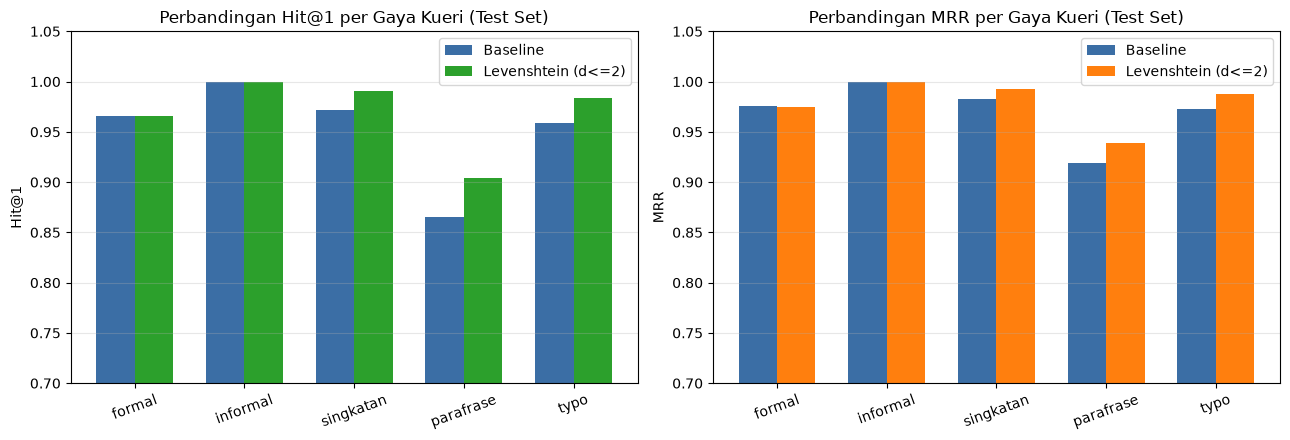

Seluruh file CSV dan grafik hasil eksperimen Levenshtein berhasil disimpan.


In [17]:
x = np.arange(len(order))
width = 0.35

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Bar chart Hit@1
ax[0].bar(x - width/2, per_gaya_df["Hit@1_Baseline"], width, label="Baseline", color="#3b6ea5")
ax[0].bar(x + width/2, per_gaya_df["Hit@1_Levenshtein"], width, label=f"Levenshtein (d<={best_threshold})", color="#2ca02c")
ax[0].set_title("Perbandingan Hit@1 per Gaya Kueri (Test Set)")
ax[0].set_xticks(x)
ax[0].set_xticklabels(order, rotation=20)
ax[0].set_ylim(0.7, 1.05)
ax[0].set_ylabel("Hit@1")
ax[0].grid(axis="y", alpha=0.3)
ax[0].legend()

# Bar chart MRR
ax[1].bar(x - width/2, per_gaya_df["MRR_Baseline"], width, label="Baseline", color="#3b6ea5")
ax[1].bar(x + width/2, per_gaya_df["MRR_Levenshtein"], width, label=f"Levenshtein (d<={best_threshold})", color="#ff7f0e")
ax[1].set_title("Perbandingan MRR per Gaya Kueri (Test Set)")
ax[1].set_xticks(x)
ax[1].set_xticklabels(order, rotation=20)
ax[1].set_ylim(0.7, 1.05)
ax[1].set_ylabel("MRR")
ax[1].grid(axis="y", alpha=0.3)
ax[1].legend()

plt.tight_layout()
plt.savefig("fig_exp2_levenshtein_vs_baseline_test.png", dpi=150)
plt.show()

# Simpan tabel hasil eksperimen ke CSV untuk pelaporan artikel SINTA 4
tuning_df.to_csv("hasil_tuning_levenshtein_dev.csv", index=False)
summary_test.to_csv("hasil_ringkasan_levenshtein_test.csv", index=False)
per_gaya_df.to_csv("hasil_per_gaya_levenshtein_test.csv", index=False)
print("Seluruh file CSV dan grafik hasil eksperimen Levenshtein berhasil disimpan.")

In [18]:
# Menampilkan kasus kueri di Test Set yang mengalami peningkatan peringkat (membaik)
# maupun penurunan peringkat (memburuk akibat over-correction) setelah Levenshtein
perubahan_kasus = []

for _, row in test_df.iterrows():
    true_doc = row["relevant_doc_id"]
    
    # Baseline rank
    q_base = preprocess_standard(row["query_text"])
    s_base = bm25.get_scores(q_base)
    r_base = [doc_ids[i] for i in np.argsort(s_base)[::-1]].index(true_doc) + 1
    
    # Levenshtein rank
    q_lev = preprocess_levenshtein(row["query_text"], best_threshold, vocab_acuan, vocab_freq)
    s_lev = bm25.get_scores(q_lev)
    r_lev = [doc_ids[i] for i in np.argsort(s_lev)[::-1]].index(true_doc) + 1
    
    if r_base != r_lev:
        perubahan_kasus.append({
            "query_id": row["query_id"],
            "gaya_kueri": row["gaya_kueri"],
            "query_text": row["query_text"],
            "tokens_base": q_base,
            "tokens_lev": q_lev,
            "rank_base": r_base,
            "rank_lev": r_lev,
            "status": "Membaik" if r_lev < r_base else "Memburuk (Over-correction)"
        })

perubahan_df = pd.DataFrame(perubahan_kasus)
print(f"Total kueri yang mengalami perubahan peringkat dokumen relevan: {len(perubahan_df)}")
print(perubahan_df["status"].value_counts())
display(perubahan_df.head(15))

Total kueri yang mengalami perubahan peringkat dokumen relevan: 13
status
Membaik                       10
Memburuk (Over-correction)     3
Name: count, dtype: int64


,query_id,gaya_kueri,query_text,tokens_base,tokens_lev,rank_base,rank_lev,status
0,Q0040,parafrase,"akun tim saya belum di verifikasi, saya tidak bisa menambahkannya sebagai anggota tim","[akun, tim, verifikasi, tambah, anggota, tim]","[akun, nim, verifikasi, tambah, anggota, nim]",2,3,Memburuk (Over-correction)
1,Q0121,parafrase,"Mohon info, seperti apa langkah registrasi akun mahasiswa di SiPi?","[mohon, info, apa, langkah, registrasi, akun, mahasiswa, sipi]","[mohon, info, apa, lengkap, registrasi, akun, mahasiswa, sipi]",3,1,Membaik
2,Q0052,singkatan,sblm pi dokumen apa aja yg hrs didownload,"[sblm, pi, dokumen, apa, aja, yg, hrs, didownload]","[sblm, pi, dokumen, apa, apa, yg, hrs, didownload]",2,1,Membaik
3,Q0111,singkatan,gmn cra registrasi akun mahasiswa di SiPi?,"[gmn, cra, registrasi, akun, mahasiswa, sipi]","[gmn, cara, registrasi, akun, mahasiswa, sipi]",2,1,Membaik
4,Q0120,parafrase,Seperti apa langkah registrasi akun mahasiswa di SiPi?,"[apa, langkah, registrasi, akun, mahasiswa, sipi]","[apa, lengkap, registrasi, akun, mahasiswa, sipi]",2,1,Membaik
5,Q0004,parafrase,langkah-langkah membuat akun baru di sistem SiPi itu seperti apa,"[langkah, langkah, buat, akun, baru, sistem, sipi, apa]","[lengkap, lengkap, buat, akun, baru, sistem, sipi, apa]",2,1,Membaik
6,Q0104,singkatan,"sdh seminggu lbh upload laporan blm diverif, prlu nunggu aj kah","[sdh, minggu, lbh, upload, lapor, blm, diverif, prlu, nunggu, aj]","[sdh, lbh, upload, lapor, blm, diverif, perlu, tunggu, aj]",8,1,Membaik
7,Q0035,typo,cra bkin pengelompokan pi,"[cra, bkin, kelompok, pi]","[cara, bkin, kelompok, pi]",2,1,Membaik
8,Q0047,formal,"perusahaan yang dituju sudah ada 2 tim yang mengajukan dan sudah batas maksimal, apakah ada solusi agar kami tetap b...","[usaha, tuju, 2, tim, aju, batas, maksimal, solusi, tetap, pi, sana]","[usaha, tuju, 2, nim, aju, batas, maksimal, solusi, tetap, pi]",24,26,Memburuk (Over-correction)
9,Q0475,typo,bagamana cara melakukan pengajuan Selsai PI di SiPi,"[bagamana, cara, laku, aju, selsai, pi, sipi]","[bagaimana, cara, laku, aju, selesai, pi, sipi]",3,1,Membaik
